# 05 - Exploratory Data Analysis

> **Scope note.** This is the first-pass EDA of the project, kept as a record together with the figures it wrote: it
> covers the original four crops and the GAEZ v5 product at ~9 km. Later notebooks extended the data (07: irrigated
> scenario, 08: ten crops, 10: GCS 2024, 12: GAEZ v5 at 1 km). The current exploratory analysis of every column, at
> both GAEZ resolutions, is the 'Exploratory Analysis' page of the dashboard (`scripts/dashboard`), and the modeling
> notebooks in `scripts/modeling` work on the 1 km target.

First real EDA pass, now that everything sits on the same 1km grid in `tabular_features.csv`. Covers distributions, correlations between features, a couple of physical sanity checks (does elevation vs temperature look right, do two independent rainfall sources roughly agree), land cover breakdown, and GAEZ suitability class distribution per crop.

In [1]:
%matplotlib inline
# force the standard static-PNG inline renderer - some IDE/Jupyter front-ends default
# to a slower or buggy interactive backend that can make multi-panel plots hang

# add scripts/download to sys.path so we can `from common import ...`
import os, sys
from pathlib import Path

NOTEBOOK_DIR = Path(os.path.abspath("."))
if NOTEBOOK_DIR.name != "preprocessing":
    NOTEBOOK_DIR = NOTEBOOK_DIR / "scripts" / "preprocessing"
os.chdir(NOTEBOOK_DIR)

PROJECT_ROOT = NOTEBOOK_DIR.parents[1]
DOWNLOAD_DIR = PROJECT_ROOT / "scripts" / "download"
if str(DOWNLOAD_DIR) not in sys.path:
    sys.path.insert(0, str(DOWNLOAD_DIR))

print("cwd:", os.getcwd())

cwd: D:\Softwares\AnacondaProjects\GeoSuitability_AI_Analytics\scripts\preprocessing


## 1. Load the feature table

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from common import PROCESSED_DIR

FEATURES_PATH = PROCESSED_DIR / "features" / "tabular_features.csv"
GRID_PATH = PROCESSED_DIR / "grid" / "grid_1km.gpkg"

df = pd.read_csv(FEATURES_PATH)
grid = gpd.read_file(GRID_PATH)

print(f"{len(df)} rows, {len(df.columns)} columns")
df.head()

9333 rows, 37 columns


,grid_id,row,col,lon,lat,bio1_temp_mean_c,bio12_precip_annual_mm,bio15_precip_seasonality,chirps_annual_mean_mm,chirps_annual_std_mm,...,landcover_majority,cropland_pct,soil_data_interpolated,soil_ph_raw,soil_soc_raw,soil_nitrogen_raw,soil_clay_pct_raw,soil_sand_pct_raw,soil_cec_raw,soil_bulk_density_raw
0,BTN_0000_0048,0,48,105.538731,-7.033623,25.748749,3203.0,40.268768,3676.410061,813.406544,...,80.0,0.0,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,BTN_0001_0048,1,48,105.538721,-7.024577,25.748749,3203.0,40.268768,3676.410061,813.406544,...,80.0,0.0,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,BTN_0001_0049,1,49,105.547775,-7.024567,25.791666,3204.0,40.433338,3675.032259,791.563944,...,80.0,0.0,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,BTN_0002_0049,2,49,105.547764,-7.015521,25.791666,3204.0,40.433338,3675.032259,791.563944,...,10.0,0.0,False,52.5,918.7,496.2,409.4,244.6,296.2,102.6
4,BTN_0002_0050,2,50,105.556818,-7.015511,25.791666,3204.0,40.433338,3673.654444,770.283611,...,10.0,0.0,False,52.0,961.0,483.6,391.4,249.2,309.5,102.9


## 1b. How many cells, and what does one of them represent?

In [3]:
CELL_SIZE_KM = 1.0  # must match CELL_SIZE_M in 03_build_analysis_grid.ipynb
n_cells = len(df)
total_area_km2 = n_cells * CELL_SIZE_KM ** 2

print(f"Total grid cells (rows in this table): {n_cells:,}")
print(f"Each cell = {CELL_SIZE_KM} km x {CELL_SIZE_KM} km = {CELL_SIZE_KM**2:.0f} km2 on the ground")
print(f"Total area covered: {total_area_km2:,.0f} km2 (Banten's actual area is ~9,663 km2)")
print()
print("This 1km grid is NOT the same resolution as the source rasters - each row here")
print("is built by aggregating (zonal statistics) much finer/coarser rasters onto one")
print("1km cell:")
print("  - Sentinel-2 (10m):      ~10,000 raw pixels feed into one cell")
print("  - SoilGrids (250m):      ~16 raw pixels feed into one cell")
print("  - DEM (30m):             ~1,100 raw pixels feed into one cell")
print("  - WorldClim (~4.6km):    one cell shares its value with ~20 neighboring cells")
print("  - GAEZ (~9.2km):         one cell shares its value with ~85 neighboring cells")
print()
print("So '1 pixel' in this table means 1 grid cell = 1 km2 on the ground, not 1 raw")
print("satellite pixel - the resolution differs by source, this grid is the common")
print("unit everything gets resampled onto.")

Total grid cells (rows in this table): 9,333
Each cell = 1.0 km x 1.0 km = 1 km2 on the ground
Total area covered: 9,333 km2 (Banten's actual area is ~9,663 km2)

This 1km grid is NOT the same resolution as the source rasters - each row here
is built by aggregating (zonal statistics) much finer/coarser rasters onto one
1km cell:
  - Sentinel-2 (10m):      ~10,000 raw pixels feed into one cell
  - SoilGrids (250m):      ~16 raw pixels feed into one cell
  - DEM (30m):             ~1,100 raw pixels feed into one cell
  - WorldClim (~4.6km):    one cell shares its value with ~20 neighboring cells
  - GAEZ (~9.2km):         one cell shares its value with ~85 neighboring cells

So '1 pixel' in this table means 1 grid cell = 1 km2 on the ground, not 1 raw
satellite pixel - the resolution differs by source, this grid is the common
unit everything gets resampled onto.


## 2. Overview - dtypes & missing values

In [4]:
print("Column dtypes:")
print(df.dtypes)
print()
print("Missing values per column:")
missing = df.isna().sum()
print(missing[missing > 0] if missing.any() else "(none - clean table)")

Column dtypes:
grid_id                         str
row                           int64
col                           int64
lon                         float64
lat                         float64
bio1_temp_mean_c            float64
bio12_precip_annual_mm      float64
bio15_precip_seasonality    float64
chirps_annual_mean_mm       float64
chirps_annual_std_mm        float64
soil_ph                     float64
soil_soc                    float64
soil_nitrogen               float64
soil_clay_pct               float64
soil_sand_pct               float64
soil_cec                    float64
soil_bulk_density           float64
elevation_mean_m            float64
slope_mean_deg              float64
gaez_class_rice             float64
gaez_class_maize            float64
gaez_class_cassava          float64
gaez_class_soybean          float64
gaez_index_rice             float64
gaez_index_maize            float64
gaez_index_cassava          float64
gaez_index_soybean          float64
landcover_maj

## 3. Summary statistics

In [5]:
CONTINUOUS_COLS = [
    "bio1_temp_mean_c", "bio12_precip_annual_mm", "bio15_precip_seasonality",
    "chirps_annual_mean_mm", "chirps_annual_std_mm",
    "soil_ph", "soil_soc", "soil_nitrogen", "soil_clay_pct", "soil_sand_pct", "soil_cec", "soil_bulk_density",
    "elevation_mean_m", "slope_mean_deg", "cropland_pct",
]
df[CONTINUOUS_COLS].describe().T

,count,mean,std,min,25%,50%,75%,max
bio1_temp_mean_c,9333.0,25.151288,1.782467,15.602750,24.735834,25.588333,26.319000,27.382166
bio12_precip_annual_mm,9333.0,2949.495571,733.907694,1627.000000,2297.000000,3117.250000,3365.500000,4400.000000
bio15_precip_seasonality,9333.0,39.017321,9.178219,18.668436,32.928913,40.104748,44.315643,69.835556
chirps_annual_mean_mm,9333.0,3438.848072,757.793808,1692.451595,2697.596951,3681.170197,4082.883632,5029.849386
chirps_annual_std_mm,9333.0,580.841676,130.283880,210.949321,489.051111,616.177888,674.936208,1054.451871
soil_ph,9333.0,52.721407,1.335863,47.560000,51.850000,52.560000,53.440000,58.440000
soil_soc,9333.0,798.517776,203.705542,384.333333,674.319955,754.916667,873.840000,1748.160000
soil_nitrogen,9333.0,409.627874,79.157439,231.333333,343.333333,422.898551,464.606061,763.320000
soil_clay_pct,9333.0,400.676900,49.886561,283.000000,363.812500,397.440000,435.400000,555.960000
soil_sand_pct,9333.0,223.455056,46.410670,110.000000,188.200000,223.000000,257.520000,362.600000


## 4. Distributions

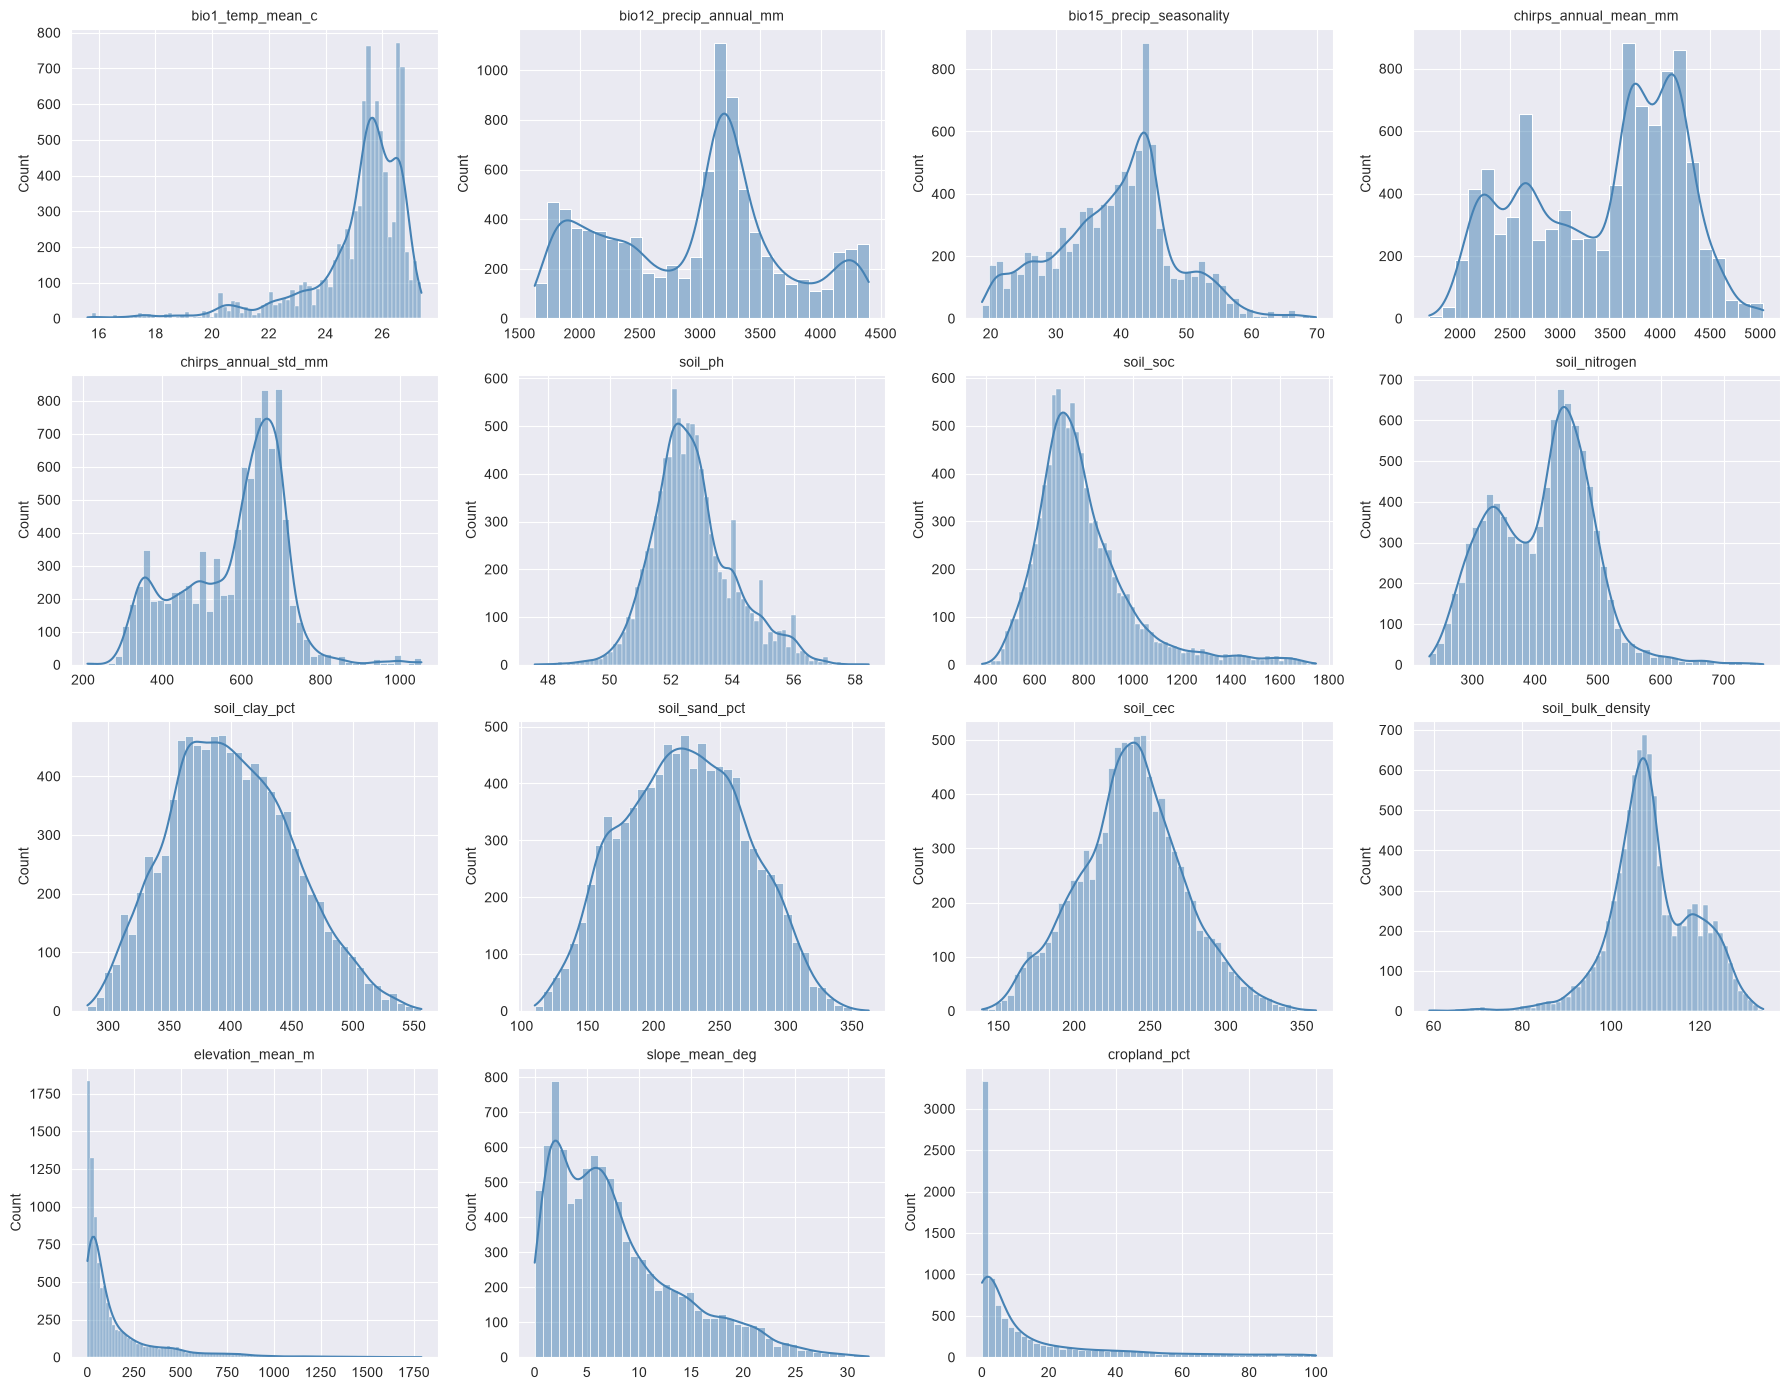

In [6]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.flatten()
for ax, col in zip(axes, CONTINUOUS_COLS):
    sns.histplot(df[col].dropna(), ax=ax, kde=True, color="steelblue")
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
for ax in axes[len(CONTINUOUS_COLS):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Correlation between features

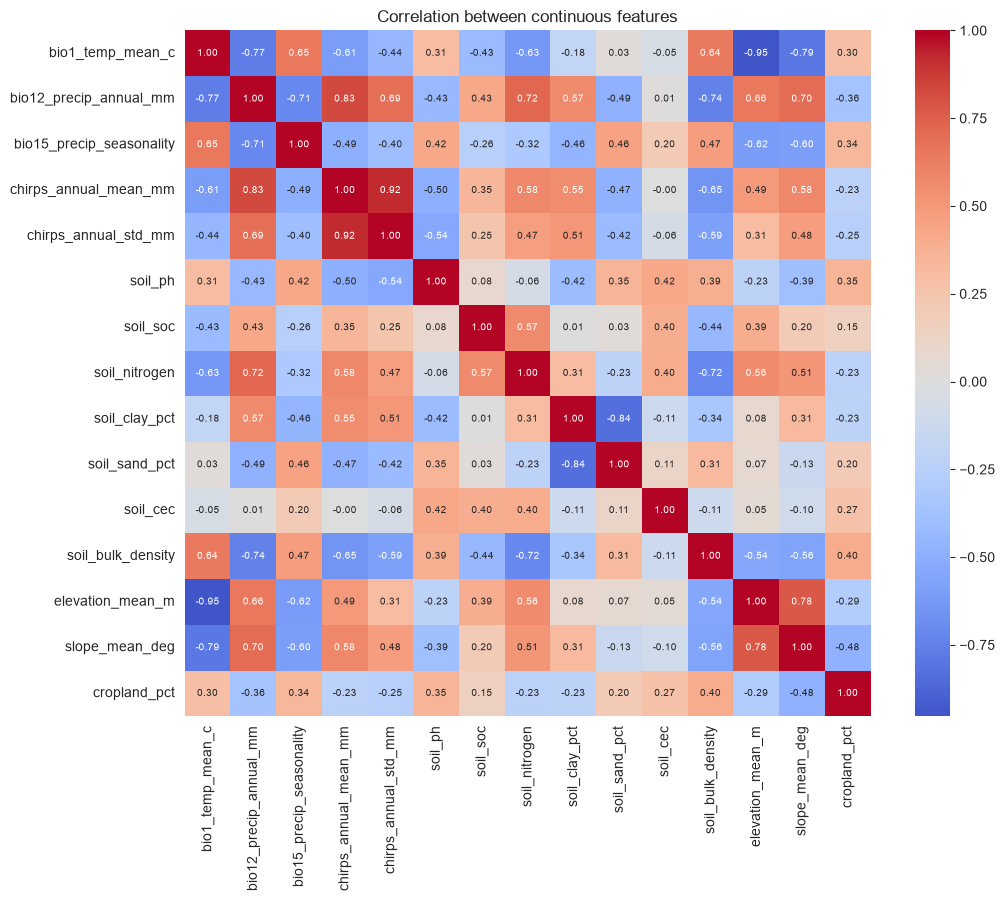

In [7]:
corr = df[CONTINUOUS_COLS].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", square=True, ax=ax,
            annot_kws={"size": 7})
ax.set_title("Correlation between continuous features")
plt.tight_layout()
plt.show()

## 6. Sanity checks - do the relationships make physical sense?

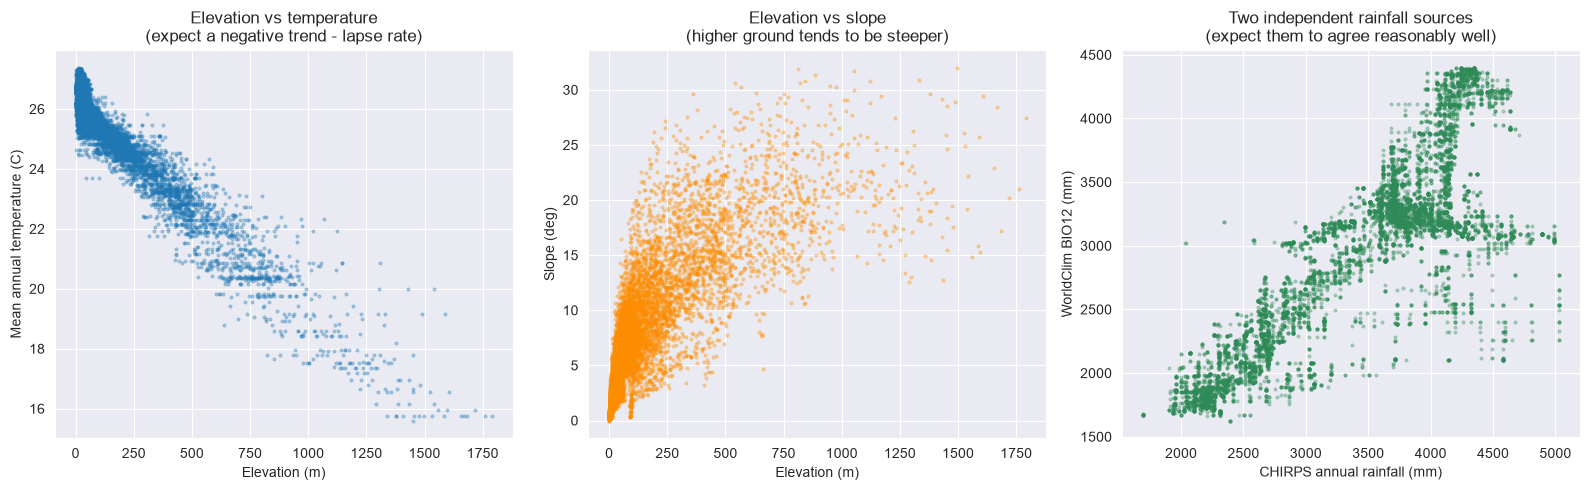

In [8]:
# Quick real-world sanity checks - do the relationships make physical sense?
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].scatter(df["elevation_mean_m"], df["bio1_temp_mean_c"], s=4, alpha=0.3)
axes[0].set_xlabel("Elevation (m)")
axes[0].set_ylabel("Mean annual temperature (C)")
axes[0].set_title("Elevation vs temperature\n(expect a negative trend - lapse rate)")

axes[1].scatter(df["elevation_mean_m"], df["slope_mean_deg"], s=4, alpha=0.3, color="darkorange")
axes[1].set_xlabel("Elevation (m)")
axes[1].set_ylabel("Slope (deg)")
axes[1].set_title("Elevation vs slope\n(higher ground tends to be steeper)")

axes[2].scatter(df["chirps_annual_mean_mm"], df["bio12_precip_annual_mm"], s=4, alpha=0.3, color="seagreen")
axes[2].set_xlabel("CHIRPS annual rainfall (mm)")
axes[2].set_ylabel("WorldClim BIO12 (mm)")
axes[2].set_title("Two independent rainfall sources\n(expect them to agree reasonably well)")

plt.tight_layout()
plt.show()

## 7. Land cover breakdown

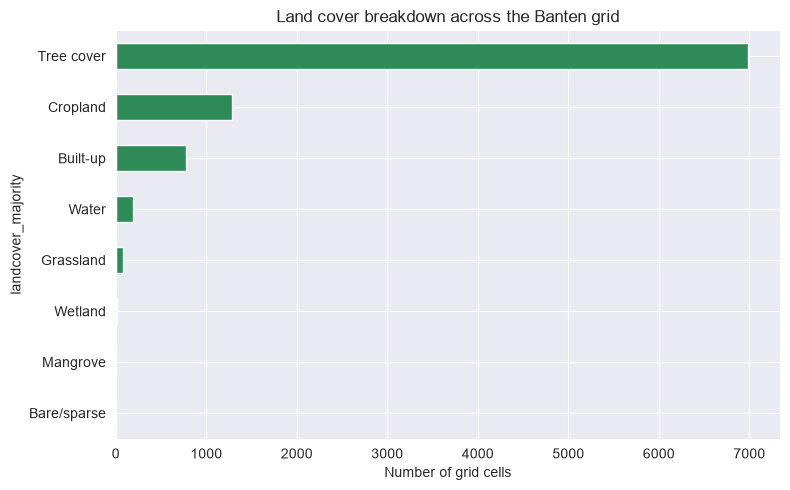

landcover_majority
Tree cover     6989
Cropland       1282
Built-up        772
Water           193
Grassland        76
Wetland          12
Mangrove          7
Bare/sparse       2
Name: count, dtype: int64

13.7% of all cells are cropland


In [9]:
LANDCOVER_LABELS = {
    10: "Tree cover", 20: "Shrubland", 30: "Grassland", 40: "Cropland",
    50: "Built-up", 60: "Bare/sparse", 70: "Snow/ice", 80: "Water",
    90: "Wetland", 95: "Mangrove", 100: "Moss/lichen",
}

counts = df["landcover_majority"].map(LANDCOVER_LABELS).value_counts()
fig, ax = plt.subplots(figsize=(8, 5))
counts.plot(kind="barh", ax=ax, color="seagreen")
ax.set_xlabel("Number of grid cells")
ax.set_title("Land cover breakdown across the Banten grid")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

print(counts)
print(f"\n{counts.get('Cropland', 0) / len(df):.1%} of all cells are cropland")

## 8. GAEZ suitability class distribution per crop

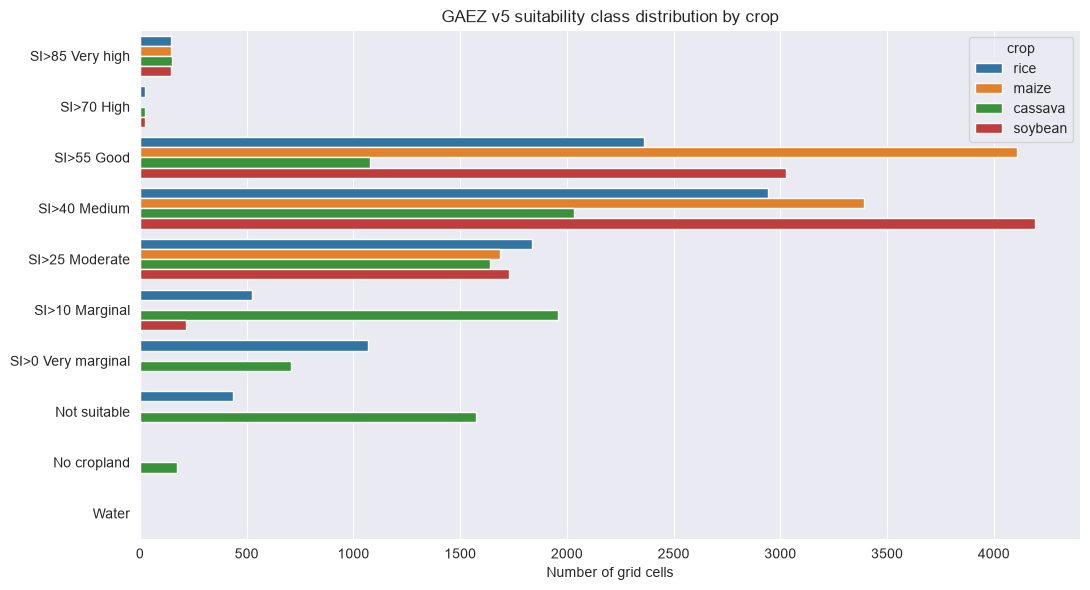

In [10]:
GAEZ_CLASS_LABELS = {
    9: "SI>85 Very high", 8: "SI>70 High", 7: "SI>55 Good", 6: "SI>40 Medium",
    5: "SI>25 Moderate", 4: "SI>10 Marginal", 3: "SI>0 Very marginal",
    2: "Not suitable", 1: "No cropland", 0: "Water", np.nan: "No data",
}
GAEZ_COLS = ["gaez_class_rice", "gaez_class_maize", "gaez_class_cassava", "gaez_class_soybean"]

gaez_long = df[GAEZ_COLS].rename(columns=lambda c: c.replace("gaez_class_", "")).melt(
    var_name="crop", value_name="class"
)
gaez_long["class_label"] = gaez_long["class"].map(GAEZ_CLASS_LABELS)

order = [GAEZ_CLASS_LABELS[k] for k in sorted(GAEZ_CLASS_LABELS.keys(), reverse=True) if not pd.isna(k)]

fig, ax = plt.subplots(figsize=(11, 6))
sns.countplot(data=gaez_long, y="class_label", hue="crop", order=order, ax=ax)
ax.set_xlabel("Number of grid cells")
ax.set_ylabel("")
ax.set_title("GAEZ v5 suitability class distribution by crop")
plt.tight_layout()
plt.show()

## 9. Land cover vs rice suitability

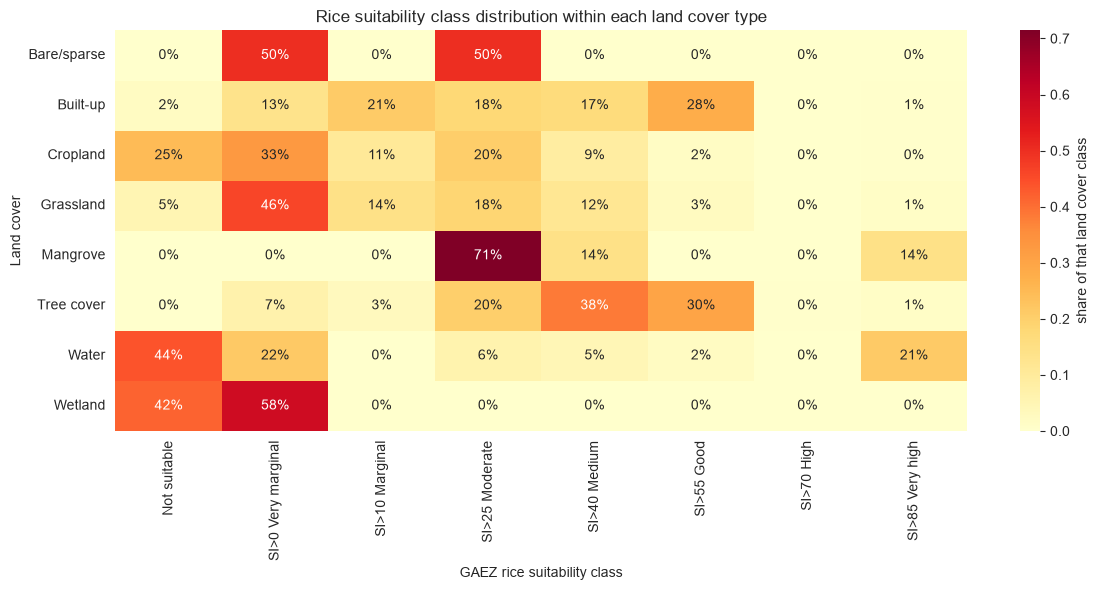

In [11]:
# Does "not suitable" line up with built-up/water land cover, as expected?
ct = pd.crosstab(
    df["landcover_majority"].map(LANDCOVER_LABELS),
    df["gaez_class_rice"].map(GAEZ_CLASS_LABELS),
    normalize="index",
)
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(ct, cmap="YlOrRd", annot=True, fmt=".0%", ax=ax, cbar_kws={"label": "share of that land cover class"})
ax.set_title("Rice suitability class distribution within each land cover type")
ax.set_xlabel("GAEZ rice suitability class")
ax.set_ylabel("Land cover")
plt.tight_layout()
plt.show()

## 10. How much of the soil data is interpolated?

In [12]:
# How much of the soil data is interpolated vs directly measured, and does it
# skew any particular land cover type?
if "soil_data_interpolated" in df.columns:
    print(f"{df['soil_data_interpolated'].sum()} / {len(df)} cells have interpolated soil data "
          f"({df['soil_data_interpolated'].mean():.1%})")
    breakdown = df[df["soil_data_interpolated"]]["landcover_majority"].map(LANDCOVER_LABELS).value_counts()
    print()
    print("Land cover breakdown of the interpolated cells:")
    print(breakdown)

1439 / 9333 cells have interpolated soil data (15.4%)

Land cover breakdown of the interpolated cells:
landcover_majority
Built-up       616
Cropland       381
Tree cover     281
Water          114
Grassland       42
Wetland          4
Bare/sparse      1
Name: count, dtype: int64


## 11. Build a unified label - best crop per cell

Turns the 4 GAEZ **Suitability Index** columns (continuous, 0-10000) into a single categorical **label** per cell: the argmax rule from the original project plan - pick whichever crop has the highest index, mark it "not recommended" below a minimum score, and flag near-ties as a multi-commodity zone.

**Why Index and not Class**: we first tried this with the categorical Suitability *Class* (0-9) instead, and it was nearly useless - 83% of cells had an *exact* tie between the top two crops (many cells have rice/maize/soybean literally at the same class number; GAEZ's class boundaries are just too coarse to rank similar staple crops against each other at ~9km resolution). The continuous Index has ~9,900 distinct values instead of 10, which is enough resolution to actually differentiate. Thresholds below are a direct scale-up of the original plan's 0-100 rule (`<50` -> not recommended, `<5` point gap -> tie) to the Index's 0-10000 scale.

In [13]:
import numpy as np

# categorical Class version, kept only to show *why* we switched to the Index below
GAEZ_CLASS_COLS = ["gaez_class_rice", "gaez_class_maize", "gaez_class_cassava", "gaez_class_soybean"]
class_vals = df[GAEZ_CLASS_COLS].to_numpy(dtype=float)
class_sorted = np.sort(class_vals, axis=1)
class_tie_rate = (class_sorted[:, -1] == class_sorted[:, -2]).mean()
print(f"Class-based exact-tie rate: {class_tie_rate:.1%} (this is why we don't use gaez_class_* for the label)")

# continuous Index version - this is what actually becomes the label
GAEZ_COLS = ["gaez_index_rice", "gaez_index_maize", "gaez_index_cassava", "gaez_index_soybean"]
CROP_NAMES = {
    "gaez_index_rice": "Padi", "gaez_index_maize": "Jagung",
    "gaez_index_cassava": "Singkong", "gaez_index_soybean": "Kedelai",
}

NOT_RECOMMENDED_THRESHOLD = 5000  # index < 50/100 equivalent -> not recommended (from the original plan)
TIE_THRESHOLD = 500  # top two crops within 5/100 equivalent of each other -> multi-commodity zone

gaez_vals = df[GAEZ_COLS].to_numpy(dtype=float)
best_idx = np.nanargmax(gaez_vals, axis=1)
best_index = np.nanmax(gaez_vals, axis=1)

sorted_vals = np.sort(gaez_vals, axis=1)
second_best_index = sorted_vals[:, -2]

best_crop = np.array([CROP_NAMES[GAEZ_COLS[i]] for i in best_idx])

label = best_crop.copy().astype(object)
label[best_index < NOT_RECOMMENDED_THRESHOLD] = "Tidak direkomendasikan"
tie_mask = (best_index - second_best_index <= TIE_THRESHOLD) & (best_index >= NOT_RECOMMENDED_THRESHOLD)
label[tie_mask] = "Zona multi-komoditas"

df["best_crop"] = best_crop
df["best_crop_index"] = best_index
df["label"] = label

not_recommended_share = (df["label"] == "Tidak direkomendasikan").mean()
print(f"\nIndex-based exact-tie rate: {(best_index == second_best_index).mean():.1%}")
print(df["label"].value_counts())
print(f"\n{not_recommended_share:.1%} of cells are not recommended for any of the 4 crops")

Class-based exact-tie rate: 83.5% (this is why we don't use gaez_class_* for the label)

Index-based exact-tie rate: 0.5%
label
Tidak direkomendasikan    6179
Singkong                  2710
Zona multi-komoditas       444
Name: count, dtype: int64

66.2% of cells are not recommended for any of the 4 crops


## 12. Describe features grouped by label

In [14]:
label_order = ["Padi", "Jagung", "Singkong", "Kedelai", "Zona multi-komoditas", "Tidak direkomendasikan"]
label_order = [l for l in label_order if l in df["label"].unique()]

print("Cell count per label:")
print(df["label"].value_counts().reindex(label_order))

print("\nMean of each continuous feature, per label:")
df.groupby("label")[CONTINUOUS_COLS].mean().reindex(label_order).T

Cell count per label:
label
Singkong                  2710
Zona multi-komoditas       444
Tidak direkomendasikan    6179
Name: count, dtype: int64

Mean of each continuous feature, per label:


label,Singkong,Zona multi-komoditas,Tidak direkomendasikan
bio1_temp_mean_c,26.224777,26.631997,24.574077
bio12_precip_annual_mm,2560.425461,1781.530968,3204.060433
bio15_precip_seasonality,41.941188,55.715070,36.535127
chirps_annual_mean_mm,3175.419767,2177.419073,3645.024668
chirps_annual_std_mm,537.737064,348.792169,616.420811
soil_ph,53.102276,54.931084,52.395586
soil_soc,821.747294,769.966141,790.381335
soil_nitrogen,375.804082,377.144908,426.796496
soil_clay_pct,388.880850,338.538723,410.315457
soil_sand_pct,227.195438,287.844562,217.187800


## 13. Map the label - recommended crop per cell

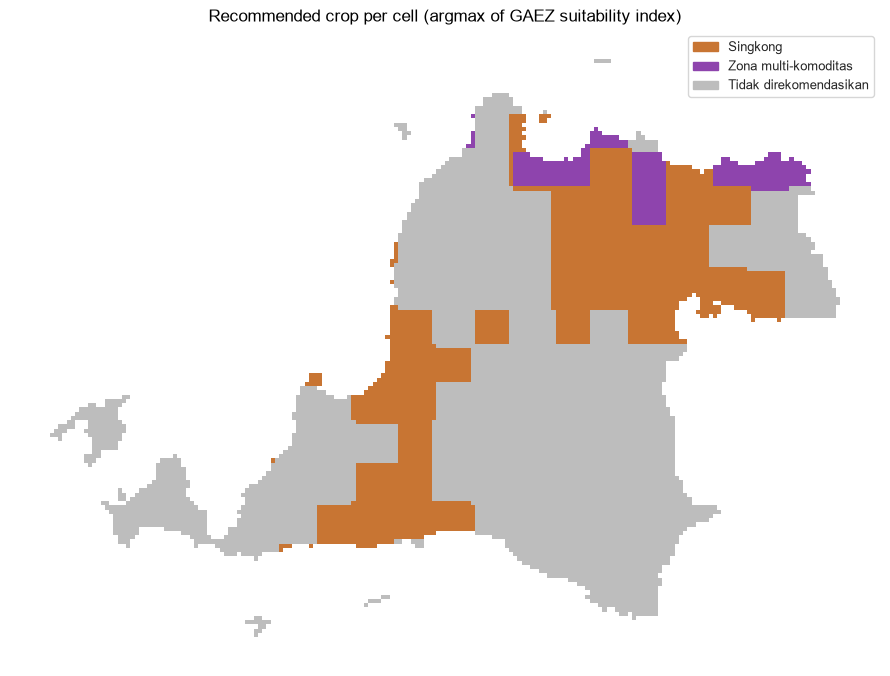

Saved to crop_recommendation_map.png - open that file directly if colors look wrong inline.


In [15]:
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches

# same palette as the original project color scheme (Ringkasan_Project doc SS11.2)
CROP_COLORS = {
    "Padi": "#E53935",
    "Jagung": "#FDD835",
    "Singkong": "#C87533",
    "Kedelai": "#43A047",
    "Zona multi-komoditas": "#8E44AD",
    "Tidak direkomendasikan": "#BDBDBD",
}

merged_label = grid.merge(df[["grid_id", "label"]], on="grid_id", how="left")
merged_label["label_code"] = pd.Categorical(merged_label["label"], categories=label_order).codes
cmap = mcolors.ListedColormap([CROP_COLORS[l] for l in label_order])

fig, ax = plt.subplots(figsize=(9, 9))
merged_label.plot(
    column="label_code", cmap=cmap, ax=ax, edgecolor="none",
    vmin=-0.5, vmax=len(label_order) - 0.5,
)
handles = [mpatches.Patch(color=CROP_COLORS[l], label=l) for l in label_order]
ax.legend(handles=handles, loc="upper right", fontsize=9, facecolor="white")
ax.set_title("Recommended crop per cell (argmax of GAEZ suitability index)", color="black")
ax.axis("off")
plt.tight_layout()
plt.savefig("crop_recommendation_map.png", dpi=150, facecolor="white")
plt.show()
print("Saved to crop_recommendation_map.png - open that file directly if colors look wrong inline.")

## 14. Feature distributions by label

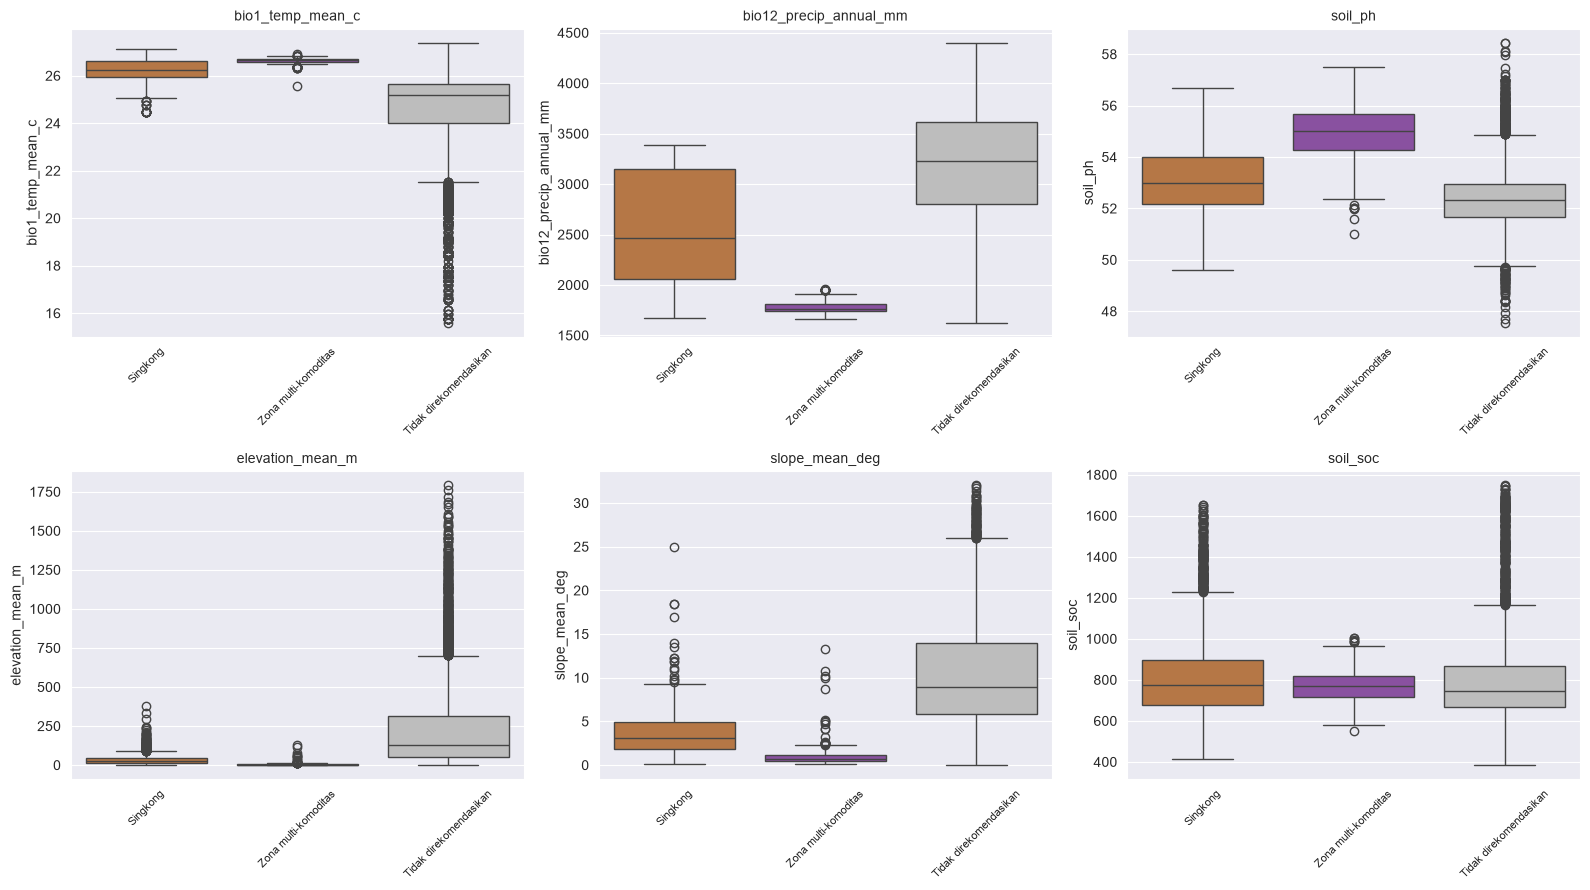

Saved to feature_distributions_by_label.png


In [16]:
plot_features = [
    "bio1_temp_mean_c", "bio12_precip_annual_mm", "soil_ph",
    "elevation_mean_m", "slope_mean_deg", "soil_soc",
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, feat in zip(axes.flatten(), plot_features):
    sns.boxplot(
        data=df, x="label", y=feat, order=label_order, ax=ax,
        hue="label", palette=CROP_COLORS, legend=False,
    )
    ax.set_title(feat, fontsize=10)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45, labelsize=8)

plt.tight_layout()
plt.savefig("feature_distributions_by_label.png", dpi=130, facecolor="white")
plt.show()
print("Saved to feature_distributions_by_label.png")